In [2]:
import os
import torch
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = '/mnt/lustre/work/hein/hof217/stable_diffusion/x4.5-outputs'


def preview(output_folder, tensor_idx, model='sd35'):
    """
    Preview an image given an output folder name and tensor index.

    Looks up metadata.csv inside the folder for the row where
    image_index_{model} == tensor_idx, then loads and displays the tensor.

    Args:
        output_folder: Folder name (e.g. 'output_20250821_104153') relative
                       to BASE_DIR, or an absolute path.
        tensor_idx:    The image index to look up (image_index_{model} column).
        model:         Model prefix: 'sd35' or 'sd15' (default: 'sd35').
    """
    folder = output_folder if os.path.isabs(output_folder) \
             else os.path.join(BASE_DIR, output_folder)

    csv_path = os.path.join(folder, 'metadata.csv')
    df = pd.read_csv(csv_path)

    idx_col = f'image_index_{model}'
    tensor_col = f'tensor_path_{model}'

    row = df[df[idx_col] == tensor_idx]
    if row.empty:
        print(f"No entry with {idx_col}={tensor_idx} in {csv_path}")
        print(f"Available range: {df[idx_col].min()} – {df[idx_col].max()}")
        return

    row = row.iloc[0]
    tensor_path = row[tensor_col]
    # tensor_path may be relative to BASE_DIR
    if not os.path.isabs(tensor_path):
        tensor_path = os.path.join(BASE_DIR, tensor_path)

    data = torch.load(tensor_path, map_location='cpu', weights_only=False)
    img_np = data['image'].permute(1, 2, 0).numpy().clip(0, 1)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img_np)
    ax.axis('off')
    ax.set_title(
        f"[{model}] idx={tensor_idx}\n"
        f"{row.get('prompt_text', '')[:100]}",
        fontsize=8
    )
    plt.tight_layout()
    plt.show()

    print(f"  tensor : {tensor_path}")
    for col in ['prompt_text', 'category', 'prompt_type']:
        if col in row:
            print(f"  {col:12s}: {row[col]}")
    return data


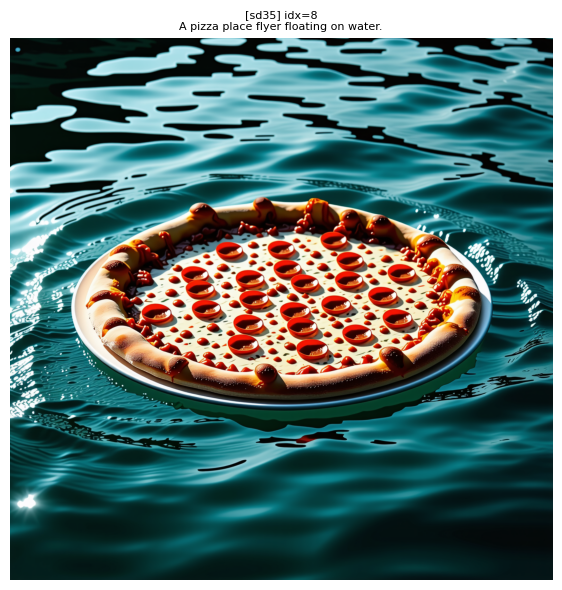

  tensor : /mnt/lustre/work/hein/hof217/stable_diffusion/x4.5-outputs/sd35_output_20250909_224443/tensors/sd35/prompt_12243438.pt
  prompt_text : A pizza place flyer floating on water.


{'image': tensor([[[0.0667, 0.0510, 0.0549,  ..., 0.2431, 0.2353, 0.3333],
          [0.0353, 0.0314, 0.0275,  ..., 0.2275, 0.2000, 0.2275],
          [0.0314, 0.0275, 0.0235,  ..., 0.1843, 0.1804, 0.1961],
          ...,
          [0.0275, 0.0235, 0.0235,  ..., 0.0235, 0.0314, 0.0275],
          [0.0392, 0.0275, 0.0275,  ..., 0.0314, 0.0314, 0.0235],
          [0.0549, 0.0314, 0.0392,  ..., 0.0275, 0.0196, 0.0392]],
 
         [[0.0902, 0.0824, 0.0863,  ..., 0.5725, 0.5451, 0.5765],
          [0.0627, 0.0627, 0.0627,  ..., 0.5451, 0.5176, 0.5490],
          [0.0588, 0.0471, 0.0471,  ..., 0.4588, 0.4588, 0.4824],
          ...,
          [0.1294, 0.1176, 0.1216,  ..., 0.0824, 0.0941, 0.0941],
          [0.1294, 0.1255, 0.1176,  ..., 0.0863, 0.0941, 0.0980],
          [0.1255, 0.1216, 0.1216,  ..., 0.0902, 0.0902, 0.0902]],
 
         [[0.0941, 0.0706, 0.0745,  ..., 0.6000, 0.5765, 0.5686],
          [0.0745, 0.0627, 0.0627,  ..., 0.5569, 0.5647, 0.5882],
          [0.0627, 0.0471, 0.04

In [5]:
# ── configure here ───────────────────────────────────────────────────────────
OUTPUT_FOLDER = 'sd35_output_20250909_224443'
# sd35_output_20250909_220646/tensors/sd35/prompt_39764032.pt,10
# sd35_output_20250909_220646/tensors/sd35/prompt_20372220.pt,13 # kid, sketching
# sd35_output_20250909_171236/tensors/sd35/prompt_53433024.pt,21 # lady, sketching
# sd35_output_20250909_224443/tensors/sd35/prompt_82034343.pt,0 # reflect, candle
# sd35_output_20250909_171236/tensors/sd35/prompt_4875625.pt,3 # reflect, person
# sd35_output_20250826_213208/tensors/sd35/prompt_69565452.pt,20 # pizza box, float
# sd35_output_20250909_224443/tensors/sd35/prompt_12243438.pt,8 # pizza flyer, float
TENSOR_IDX    = 8
MODEL         = 'sd35'   # 'sd35' or 'sd15'
# ─────────────────────────────────────────────────────────────────────────────

preview(OUTPUT_FOLDER, TENSOR_IDX, model=MODEL)


In [4]:
# # ./sd35_output_20260309_183516/metadata_pizza_20260309_183516.csv:2:phrase_58447188.pt,0 # pizza, 
# from torchvision.transforms import ToPILImage
# # 1. Path to your generated tensor file 
# # (Check your sd35_output folder for the exact filename)
# tensor_path = './sd35_output_20260309_183516/tensors/phrase_58447188.pt' 

# # 2. Load the data
# data = torch.load(tensor_path)
# images_tensors = data['images']  # This is a list of tensors
# prompts = data['prompts']

# # 3. Convert the first tensor back to a viewable image
# # Your script saved them as [C, H, W], so we convert back to PIL
# show_img = ToPILImage()(images_tensors[0])

# # 4. Display it
# plt.figure(figsize=(8, 8))
# plt.imshow(show_img)
# plt.title(f"Prompt: {prompts[0]}")
# plt.axis('off')
# plt.show()